# Random Forest dự đoán khách hàng giá trị cao

## Import thư viện và đọc dữ liệu

In [1]:
import sys, hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.inspection import permutation_importance
import sklearn
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.1


In [2]:
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(f for f in [current_dir, *current_dir.parents]
                    if (f / "data" / "raw" / "Online Retail.xlsx").exists())
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "Online Retail.xlsx"
NB_DIR = PROJECT_ROOT / "notebooks" / "06_random_forest" / "14-11-2026_an_random_forest"
FIG_DIR = NB_DIR / "figure"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing import SPECIAL_CODES, OUTLIER_COLS, OUTLIER_K, RAW_SHA256

sha = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
print("SHA-256 khớp với raw của dự án:", sha == RAW_SHA256)
assert sha == RAW_SHA256

df_raw = pd.read_excel(RAW_PATH, sheet_name="Online Retail")
print("Kích thước dữ liệu:", df_raw.shape)
df_raw.head()

SHA-256 khớp với raw của dự án: True
Kích thước dữ liệu: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Đọc dữ liệu thành công: file raw khớp SHA-256 của dự án, có 541.909 dòng và 8 cột.

## Cấu hình thí nghiệm

In [4]:
RANDOM_STATE = 42
WINDOW_START = pd.Timestamp("2010-12-01")   # đầu dữ liệu
CUTOFF = pd.Timestamp("2011-09-01")         # mốc cắt: trước = feature, từ mốc = nhãn
END_DATE = pd.Timestamp("2011-12-10")       # ngày tham chiếu RFM của bộ feature gốc
TOP_Q = 0.80                                # nhãn 1 = top 20% chi tiêu ròng giai đoạn nhãn
TEST_SIZE = 0.20

FEATURES = ["Recency", "Frequency", "Monetary", "n_stock_codes", "total_quantity", "active_days",
            "observed_span_days", "observed_tenure_days", "avg_purchase_gap_days",
            "avg_order_value", "avg_quantity_per_order"]

results = {}   # gom số liệu để tổng hợp ở cuối notebook
print("Mốc cắt:", CUTOFF.date(), "| top", round((1 - TOP_Q) * 100), "% | seed", RANDOM_STATE)

Mốc cắt: 2011-09-01 | top 20 % | seed 42


## Cohort 4.327 khách

In [5]:
FEATURE_CSV = (PROJECT_ROOT / "notebooks" / "02_baseline_kmeans" / "12-11-2026-hieu-kmeans"
               / "data" / "customer_features.csv")
ref_feat = pd.read_csv(FEATURE_CSV)
assert ref_feat["CustomerID"].is_unique
cohort_ids = set(ref_feat["CustomerID"])
results["n_cohort"] = len(cohort_ids)

print("Cột của bộ feature gốc:", list(ref_feat.columns))
print("Số khách trong cohort:", len(cohort_ids))

Cột của bộ feature gốc: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'n_stock_codes', 'total_quantity', 'active_days', 'observed_span_days', 'observed_tenure_days', 'avg_purchase_gap_days', 'avg_order_value', 'avg_quantity_per_order']
Số khách trong cohort: 4327


## Làm sạch dòng mua và dòng hủy

Dòng mua dùng đúng quy tắc của `clean_data`: bỏ dòng trùng, hóa đơn hủy, Quantity/Price không dương,
mã dịch vụ và ngoại lai IQR x 3 trên log1p. Dòng hủy (hóa đơn C) được lọc bằng cùng bộ mã dịch vụ và
cùng ngưỡng ngoại lai (dùng |Quantity|), để không trừ hủy cho những dòng mua đã bị loại.

In [6]:
def normalise(raw):
    df = raw.rename(columns={"InvoiceNo": "Invoice", "UnitPrice": "Price", "CustomerID": "Customer ID"}).copy()
    df["Description"] = df["Description"].fillna("Unknown Product").astype(str).str.strip().str.upper()
    for col in ["Invoice", "StockCode"]:
        df[col] = df[col].astype(str).str.strip().str.upper()
    df["Country"] = df["Country"].astype(str).str.strip().replace({"EIRE": "Ireland"})
    return df.drop_duplicates()

base = normalise(df_raw)
is_cancel = base["Invoice"].str.startswith("C")
not_special = ~base["StockCode"].isin(SPECIAL_CODES)

# Dòng mua: bỏ hủy, Quantity/Price > 0, bỏ mã dịch vụ
buy_pre = base[~is_cancel & (base["Quantity"] > 0) & (base["Price"] > 0) & not_special].copy()

# Ngưỡng ngoại lai IQR x 3 trên log1p, fit trên tập dòng mua
bounds = {}
for col in OUTLIER_COLS:
    x = np.log1p(buy_pre[col])
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    bounds[col] = (q1 - OUTLIER_K * iqr, q3 + OUTLIER_K * iqr)

def within_bounds(df, quantity):
    ok = pd.Series(True, index=df.index)
    for col, series in [("Quantity", quantity), ("Price", df["Price"])]:
        x = np.log1p(series)
        lo, hi = bounds[col]
        ok &= (x >= lo) & (x <= hi)
    return ok

buy_all = buy_pre[within_bounds(buy_pre, buy_pre["Quantity"])].copy()

# Dòng hủy: có CustomerID, Price > 0, bỏ mã dịch vụ, cùng ngưỡng ngoại lai (|Quantity|)
ret_pre = base[is_cancel & base["Customer ID"].notna() & (base["Price"] > 0) & not_special].copy()
assert (ret_pre["Quantity"] < 0).all()
ret_all = ret_pre[within_bounds(ret_pre, -ret_pre["Quantity"])].copy()

def to_cohort(df):
    df = df[df["Customer ID"].notna()].copy()
    df["CustomerID"] = df["Customer ID"].astype(int)
    df["Value"] = df["Quantity"] * df["Price"]
    return df[df["CustomerID"].isin(cohort_ids)]

buy_c, ret_c = to_cohort(buy_all), to_cohort(ret_all)
assert set(buy_c["CustomerID"]) == cohort_ids, "Cohort tái dựng không trùng 4.327 khách gốc"

steps = pd.DataFrame({
    "Bước": ["Sau bỏ trùng (mọi dòng)", "Dòng mua sau lọc Quantity/Price/mã dịch vụ", "Dòng mua sau lọc ngoại lai",
             "Dòng mua của cohort", "Dòng hủy có CustomerID, sau lọc mã dịch vụ", "Dòng hủy sau lọc ngoại lai",
             "Dòng hủy của cohort"],
    "Số dòng": [len(base), len(buy_pre), len(buy_all), len(buy_c), len(ret_pre), len(ret_all), len(ret_c)],
})
results["rows"] = dict(zip(steps["Bước"], steps["Số dòng"].astype(int)))
steps

,Bước,Số dòng
0,Sau bỏ trùng (mọi dòng),536641
1,Dòng mua sau lọc Quantity/Price/mã dịch vụ,522571
2,Dòng mua sau lọc ngoại lai,522388
3,Dòng mua của cohort,390987
4,"Dòng hủy có CustomerID, sau lọc mã dịch vụ",8506
5,Dòng hủy sau lọc ngoại lai,8480
6,Dòng hủy của cohort,8376


Sau khi bỏ trùng còn 536.641 dòng. Dòng mua giữ lại 522.388 dòng (đúng bằng `data_clean.csv`), trong đó 390.987 dòng thuộc 4.327 khách của cohort, phần còn lại là dòng không có CustomerID. Dòng hủy của cohort là 8.376 dòng. Cohort tái dựng trùng 100% với 4.327 khách gốc.

## Kiểm tra: tái dựng bộ feature 12 cột từ dữ liệu sạch

In [7]:
def build_features(buy, ret, ref_date, net_returns):
    # Một dòng/khách; CustomerID chỉ là chỉ mục, không phải feature
    b = buy.copy()
    b["PurchaseDay"] = b["InvoiceDate"].dt.normalize()
    f = b.groupby("CustomerID").agg(
        LastPurchase=("InvoiceDate", "max"), FirstPurchase=("InvoiceDate", "min"),
        Frequency=("Invoice", "nunique"), Monetary=("Value", "sum"),
        n_stock_codes=("StockCode", "nunique"), total_quantity=("Quantity", "sum"),
        active_days=("PurchaseDay", "nunique"))
    f["Recency"] = (ref_date - f["LastPurchase"].dt.normalize()).dt.days
    f["observed_span_days"] = (f["LastPurchase"] - f["FirstPurchase"]).dt.total_seconds() / 86400
    f["observed_tenure_days"] = (ref_date - f["FirstPurchase"]).dt.total_seconds() / 86400

    # Mỗi hóa đơn lấy thời điểm sớm nhất; khách một hóa đơn có gap NaN (không điền 0)
    orders = (b.groupby(["CustomerID", "Invoice"], as_index=False)["InvoiceDate"].min()
                .sort_values(["CustomerID", "InvoiceDate", "Invoice"]))
    orders["gap"] = orders.groupby("CustomerID")["InvoiceDate"].diff().dt.total_seconds() / 86400
    f["avg_purchase_gap_days"] = orders.groupby("CustomerID")["gap"].mean()

    if net_returns:   # đối trừ hủy trong cùng cửa sổ; Value của dòng hủy là số âm
        f["Monetary"] = f["Monetary"] + ret.groupby("CustomerID")["Value"].sum().reindex(f.index).fillna(0.0)
    f["avg_order_value"] = f["Monetary"] / f["Frequency"]
    f["avg_quantity_per_order"] = f["total_quantity"] / f["Frequency"]
    return f[FEATURES]

# Tái dựng cả giai đoạn, chưa đối trừ, để đối chiếu với bộ feature gốc
rebuilt = build_features(buy_c, ret_c, END_DATE, net_returns=False)
reference = ref_feat.set_index("CustomerID")[FEATURES]
match = {c: bool(np.allclose(rebuilt.loc[reference.index, c], reference[c], rtol=1e-9, atol=1e-6, equal_nan=True))
         for c in FEATURES}
results["rebuild_match"] = match
print("Khớp bộ feature gốc theo từng cột:")
print(pd.Series(match).to_string())
assert all(match.values())

Khớp bộ feature gốc theo từng cột:
Recency                   True
Frequency                 True
Monetary                  True
n_stock_codes             True
total_quantity            True
active_days               True
observed_span_days        True
observed_tenure_days      True
avg_purchase_gap_days     True
avg_order_value           True
avg_quantity_per_order    True


Cả 11 feature tái dựng từ dữ liệu sạch đều khớp hoàn toàn với bộ feature gốc, nên bộ lọc và hàm `build_features` đúng với quy tắc đã dùng. Từ bước này CustomerID chỉ làm chỉ mục, không đưa vào mô hình.

## Hủy hàng trong cohort

In [8]:
ret_by = ret_c.groupby("CustomerID")["Value"].sum()
gross_by = buy_c.groupby("CustomerID")["Value"].sum()
net_by = gross_by.add(ret_by, fill_value=0.0)

n_ret = len(ret_by)
results["returns_full"] = {
    "n_customers_with_returns": int(n_ret),
    "share_customers": float(n_ret / len(cohort_ids)),
    "return_value_gbp": float(ret_by.sum()),
    "share_of_gross_monetary": float(-ret_by.sum() / gross_by.sum()),
    "n_net_le_zero": int((net_by <= 0).sum()),
    "n_return_over_half": int(((-ret_by / gross_by.reindex(ret_by.index)) > 0.5).sum()),
}
print("Khách có hủy:", n_ret, f"({n_ret / len(cohort_ids):.1%} cohort)")
print(f"Tổng giá trị hủy: {ret_by.sum():,.0f} GBP = {-ret_by.sum() / gross_by.sum():.1%} tổng Monetary gộp")
print("Khách có chi tiêu ròng <= 0 cả kỳ:", int((net_by <= 0).sum()))
print("Khách hủy hơn 50% giá trị mua:", results["returns_full"]["n_return_over_half"])

Khách có hủy: 1495 (34.6% cohort)
Tổng giá trị hủy: -217,933 GBP = 2.6% tổng Monetary gộp
Khách có chi tiêu ròng <= 0 cả kỳ: 12
Khách hủy hơn 50% giá trị mua: 25


Có 1.495 khách (34,6% cohort) từng hủy hàng, tổng 217.933 GBP, bằng 2,6% Monetary gộp. Con số này đã áp dụng cùng bộ lọc với dòng mua; nếu không lọc, giá trị hủy lớn hơn nhiều vì gồm cả đơn hủy của các dòng bị coi là ngoại lai. Có 12 khách chi tiêu ròng <= 0 cả kỳ và 25 khách hủy trên 50% giá trị mua, nên đối trừ chỉ ảnh hưởng mạnh tới một nhóm nhỏ.

## Chia giai đoạn: feature trước mốc, nhãn từ mốc

In [9]:
buy_feat = buy_c[(buy_c["InvoiceDate"] >= WINDOW_START) & (buy_c["InvoiceDate"] < CUTOFF)]
ret_feat = ret_c[(ret_c["InvoiceDate"] >= WINDOW_START) & (ret_c["InvoiceDate"] < CUTOFF)]
buy_lab = buy_c[buy_c["InvoiceDate"] >= CUTOFF]
ret_lab = ret_c[ret_c["InvoiceDate"] >= CUTOFF]

# Chống rò rỉ: dữ liệu feature hoàn toàn trước mốc, dữ liệu nhãn hoàn toàn từ mốc
assert buy_c["InvoiceDate"].min() >= WINDOW_START and buy_c["InvoiceDate"].max() < END_DATE
assert buy_feat["InvoiceDate"].max() < CUTOFF <= buy_lab["InvoiceDate"].min()
assert ret_feat["InvoiceDate"].max() < CUTOFF <= ret_lab["InvoiceDate"].min()

model_ids = sorted(buy_feat["CustomerID"].unique())
new_after = cohort_ids - set(model_ids)
results["cohort_funnel"] = {
    "n_cohort": len(cohort_ids), "n_with_features": len(model_ids), "n_new_after_cutoff": len(new_after),
    "rows_buy_feature": len(buy_feat), "rows_buy_label": len(buy_lab),
}
print("Khách trong cohort:", len(cohort_ids))
print("Khách có mua trước mốc (đưa vào mô hình):", len(model_ids))
print("Khách mới sau mốc (chưa có feature, bị loại):", len(new_after))
print("Dòng mua giai đoạn feature / nhãn:", len(buy_feat), "/", len(buy_lab))

Khách trong cohort: 4327
Khách có mua trước mốc (đưa vào mô hình): 3306
Khách mới sau mốc (chưa có feature, bị loại): 1021
Dòng mua giai đoạn feature / nhãn: 223001 / 167986


Có 3.306 khách mua trước mốc và được đưa vào mô hình. 1.021 khách (23,6% cohort) chỉ xuất hiện sau mốc nên chưa có feature, mô hình không dự đoán cho nhóm khách mới này. Các assert xác nhận dữ liệu feature hoàn toàn trước 01/09/2011 và dữ liệu nhãn hoàn toàn từ mốc trở đi, không rò rỉ thời gian.

## Tạo feature trước mốc (11 cột, bỏ CustomerID)

In [10]:
X_all = build_features(buy_feat, ret_feat, CUTOFF, net_returns=True)
assert "CustomerID" not in X_all.columns and X_all.index.name == "CustomerID"
assert list(X_all.columns) == FEATURES and X_all.index.is_unique
assert (X_all["Recency"] >= 1).all()

results["features"] = {
    "shape": list(X_all.shape),
    "n_nan_gap": int(X_all["avg_purchase_gap_days"].isna().sum()),
    "n_monetary_le_zero": int((X_all["Monetary"] <= 0).sum()),
}
print("Kích thước feature:", X_all.shape)
print("Giá trị thiếu theo cột:")
print(X_all.isna().sum()[X_all.isna().sum() > 0].to_string())
print("Khách có Monetary ròng <= 0 trước mốc:", int((X_all["Monetary"] <= 0).sum()))
X_all.describe().T[["min", "50%", "max", "mean", "std"]].round(2)

Kích thước feature: (3306, 11)
Giá trị thiếu theo cột:
avg_purchase_gap_days    1375
Khách có Monetary ròng <= 0 trước mốc: 7


,min,50%,max,mean,std
Recency,1.00,73.00,274.00,93.07,76.66
Frequency,1.00,2.00,126.00,3.42,5.55
Monetary,-141.48,531.76,175422.94,1473.14,5611.74
n_stock_codes,1.00,29.00,1188.00,49.10,66.14
total_quantity,1.00,305.50,126693.00,901.02,3514.08
active_days,1.00,2.00,78.00,3.12,4.45
observed_span_days,0.00,48.91,272.07,83.58,91.93
observed_tenure_days,0.28,184.56,273.65,176.11,77.92
avg_purchase_gap_days,0.00,45.67,259.96,58.52,45.38
avg_order_value,-141.48,268.99,9338.38,357.52,439.80


Bộ feature gồm 3.306 khách và 11 cột. Chỉ `avg_purchase_gap_days` thiếu giá trị (1.375 khách chỉ có một hóa đơn), được giữ NaN vì Random Forest xử lý trực tiếp. Có 7 khách Monetary ròng <= 0 do hủy nhiều hơn mua. Monetary lệch phải mạnh (trung vị 532, lớn nhất 175.423 GBP) nhưng không cần log hay chuẩn hóa với Random Forest.

## Tạo nhãn và chia train/test

Nhãn = 1 nếu chi tiêu ròng (đã trừ hủy) trong giai đoạn nhãn thuộc top 20% và lớn hơn 0.
Ngưỡng top 20% tính chỉ trên tập train. Việc chia stratified cần một nhãn tạm (ngưỡng trên toàn cohort);
nhãn chính thức sau đó được tính lại bằng ngưỡng của train.

Ngưỡng top 20% (train): 922 GBP
Train: (2644, 11) | nhãn 1: 529 (20.0%)
Test : (662, 11) | nhãn 1: 133 (20.1%)
Khách không mua ở giai đoạn nhãn: 40.8% | chi tiêu ròng âm: 24


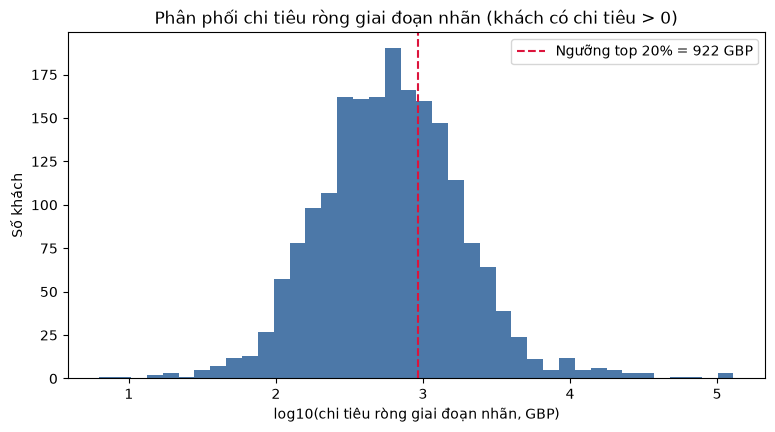

In [11]:
def net_value(buy, ret, ids):
    s = buy.groupby("CustomerID")["Value"].sum().add(ret.groupby("CustomerID")["Value"].sum(), fill_value=0.0)
    return s.reindex(ids).fillna(0.0)   # khách không mua ở giai đoạn nhãn có chi tiêu 0

net_label = net_value(buy_lab, ret_lab, X_all.index)

y_tmp = ((net_label >= net_label.quantile(TOP_Q)) & (net_label > 0)).astype(int)   # chỉ để stratify
idx_train, idx_test = train_test_split(X_all.index, test_size=TEST_SIZE, stratify=y_tmp, random_state=RANDOM_STATE)

thr_gbp = net_label.loc[idx_train].quantile(TOP_Q)      # ngưỡng chỉ từ train
y = ((net_label >= thr_gbp) & (net_label > 0)).astype(int)
X_train, X_test = X_all.loc[idx_train], X_all.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

results["label"] = {
    "thr_gbp": float(thr_gbp), "n_train": len(X_train), "n_test": len(X_test),
    "pos_train": int(y_train.sum()), "pos_test": int(y_test.sum()),
    "rate_train": float(y_train.mean()), "rate_test": float(y_test.mean()),
    "share_no_purchase_in_label": float((net_label == 0).mean()),
    "n_net_negative": int((net_label < 0).sum()),
}
print(f"Ngưỡng top 20% (train): {thr_gbp:,.0f} GBP")
print("Train:", X_train.shape, "| nhãn 1:", int(y_train.sum()), f"({y_train.mean():.1%})")
print("Test :", X_test.shape, "| nhãn 1:", int(y_test.sum()), f"({y_test.mean():.1%})")
print(f"Khách không mua ở giai đoạn nhãn: {(net_label == 0).mean():.1%} | chi tiêu ròng âm: {int((net_label < 0).sum())}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(np.log10(net_label[net_label > 0]), bins=40, color="#4C78A8")
ax.axvline(np.log10(thr_gbp), color="crimson", ls="--", label=f"Ngưỡng top 20% = {thr_gbp:,.0f} GBP")
ax.set(xlabel="log10(chi tiêu ròng giai đoạn nhãn, GBP)", ylabel="Số khách",
       title="Phân phối chi tiêu ròng giai đoạn nhãn (khách có chi tiêu > 0)")
ax.legend()
plt.savefig(FIG_DIR / "label_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Ngưỡng top 20% tính trên train là 922 GBP chi tiêu ròng. Train có 2.644 khách (529 nhãn 1, 20,0%), test có 662 khách (133 nhãn 1, 20,1%), hai tập có tỷ lệ nhãn gần như nhau. Có 40,8% khách không mua gì ở giai đoạn nhãn và 24 khách chi tiêu ròng âm, tất cả mang nhãn 0. Nhãn lệch vừa phải (khoảng 1:4), được xử lý bằng `class_weight`.

## Baseline để so sánh

Hai mốc so sánh: đoán ngẫu nhiên theo tỷ lệ nhãn, và quy tắc đơn giản dùng chính Monetary quá khứ
(khách chi nhiều trước mốc thì được xếp cao). Random Forest chỉ có giá trị nếu thắng quy tắc thứ hai.

In [12]:
def precision_at_k(y_true, score, frac=0.10):
    y_true, score = np.asarray(y_true), np.asarray(score)
    k = max(1, int(round(frac * len(y_true))))
    return y_true[np.argsort(-score, kind="stable")[:k]].mean()

def rank_metrics(y_true, score):
    p10 = precision_at_k(y_true, score)
    return {"PR-AUC": float(average_precision_score(y_true, score)), "ROC-AUC": float(roc_auc_score(y_true, score)),
            "Precision@10%": float(p10), "Lift@10%": float(p10 / np.mean(y_true))}

def class_metrics(y_true, pred):
    return {"Precision": float(precision_score(y_true, pred, zero_division=0)),
            "Recall": float(recall_score(y_true, pred)), "F1": float(f1_score(y_true, pred))}

score_base = X_test["Monetary"].to_numpy()
thr_base = X_train["Monetary"].quantile(TOP_Q)
pred_base = (X_test["Monetary"] >= thr_base).astype(int)

print(f"Quy tắc baseline: Monetary quá khứ >= {thr_base:,.0f} GBP (P80 của train)")
print({k: round(v, 3) for k, v in rank_metrics(y_test, score_base).items()})
print({k: round(v, 3) for k, v in class_metrics(y_test, pred_base).items()})

Quy tắc baseline: Monetary quá khứ >= 1,555 GBP (P80 của train)
{'PR-AUC': 0.678, 'ROC-AUC': 0.842, 'Precision@10%': 0.788, 'Lift@10%': 3.922}
{'Precision': 0.587, 'Recall': 0.609, 'F1': 0.598}


## Random Forest: tinh chỉnh siêu tham số

In [13]:
param_grid = {"min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.5]}
rf = RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs = GridSearchCV(rf, param_grid, scoring="average_precision", cv=cv, refit=True)
gs.fit(X_train, y_train)   # NaN ở avg_purchase_gap_days được Random Forest xử lý trực tiếp

cv_table = (pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
            .sort_values("rank_test_score").reset_index(drop=True))
results["grid"] = {"best_params": gs.best_params_, "best_cv_pr_auc": float(gs.best_score_)}
print("Tham số tốt nhất:", gs.best_params_)
print(f"PR-AUC trung bình 5-fold: {gs.best_score_:.3f}")
cv_table.round(4)

Tham số tốt nhất: {'max_features': 'sqrt', 'min_samples_leaf': 10}
PR-AUC trung bình 5-fold: 0.689


,params,mean_test_score,std_test_score,rank_test_score
0,"{'max_features': 'sqrt', 'min_samples_leaf': 10}",0.6888,0.0301,1
1,"{'max_features': 0.5, 'min_samples_leaf': 10}",0.6874,0.0290,2
2,"{'max_features': 'sqrt', 'min_samples_leaf': 5}",0.6846,0.0297,3
3,"{'max_features': 0.5, 'min_samples_leaf': 5}",0.6818,0.0264,4
4,"{'max_features': 'sqrt', 'min_samples_leaf': 3}",0.6792,0.0264,5
5,"{'max_features': 0.5, 'min_samples_leaf': 3}",0.6760,0.0243,6
6,"{'max_features': 'sqrt', 'min_samples_leaf': 1}",0.6640,0.0293,7
7,"{'max_features': 0.5, 'min_samples_leaf': 1}",0.6632,0.0297,8


Cấu hình tốt nhất là `max_features='sqrt'`, `min_samples_leaf=10`, PR-AUC 5-fold 0,689. PR-AUC tăng đều khi `min_samples_leaf` tăng (lá nhỏ bị overfit), nhưng độ lệch chuẩn giữa các fold khoảng 0,03 nên các cấu hình đầu bảng gần như không phân biệt được. `min_samples_leaf=10` nằm ở biên lưới, có thể thử giá trị lớn hơn.

## Chọn ngưỡng phân loại

In [14]:
best_rf = gs.best_estimator_
# Xác suất out-of-fold trên train, chọn ngưỡng cho F1 lớn nhất; test không tham gia
oof = cross_val_predict(best_rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1_curve = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
thr_f1 = float(thr[np.argmax(f1_curve)])
results["threshold"] = {"thr_f1": thr_f1, "oof_f1": float(f1_curve.max())}
print(f"Ngưỡng xác suất (F1 lớn nhất trên OOF): {thr_f1:.3f} | F1 OOF = {f1_curve.max():.3f}")

Ngưỡng xác suất (F1 lớn nhất trên OOF): 0.634 | F1 OOF = 0.624


## Đánh giá trên tập test

,PR-AUC,ROC-AUC,Precision@10%,Lift@10%
Random Forest,0.672,0.838,0.848,4.223
Baseline: Monetary quá khứ,0.678,0.842,0.788,3.922
Ngẫu nhiên (tỷ lệ nhãn),0.201,0.500,0.201,1.000


,Precision,Recall,F1
Random Forest,0.611,0.579,0.595
Baseline: Monetary quá khứ,0.587,0.609,0.598


Ma trận nhầm lẫn [hàng = thực tế 0/1, cột = dự đoán 0/1]:
[[480  49]
 [ 56  77]]
PR-AUC Random Forest, khoảng 95% bootstrap: [0.590, 0.752]
Chênh PR-AUC (RF - baseline), khoảng 95% bootstrap: [-0.035, 0.018]


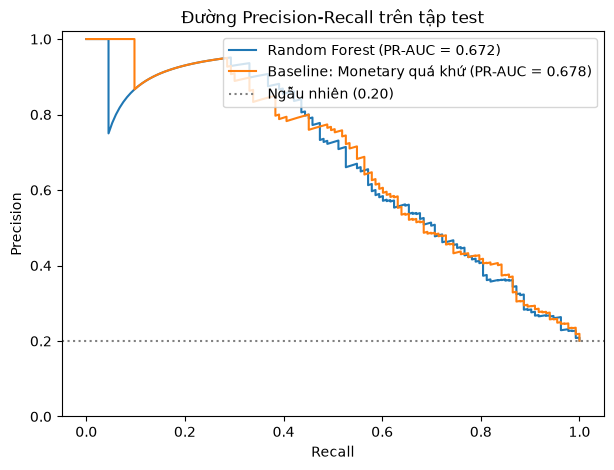

In [15]:
proba_test = best_rf.predict_proba(X_test)[:, 1]
pred_rf = (proba_test >= thr_f1).astype(int)
prev = float(y_test.mean())

rank_table = pd.DataFrame({
    "Random Forest": rank_metrics(y_test, proba_test),
    "Baseline: Monetary quá khứ": rank_metrics(y_test, score_base),
    "Ngẫu nhiên (tỷ lệ nhãn)": {"PR-AUC": prev, "ROC-AUC": 0.5, "Precision@10%": prev, "Lift@10%": 1.0},
}).T
class_table = pd.DataFrame({"Random Forest": class_metrics(y_test, pred_rf),
                            "Baseline: Monetary quá khứ": class_metrics(y_test, pred_base)}).T
cm = confusion_matrix(y_test, pred_rf)

# Bootstrap 1000 lần trên test để xem độ chắc chắn của chênh lệch PR-AUC
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
rf_ap, diff_ap = [], []
for _ in range(1000):
    ix = rng.integers(0, len(yt), len(yt))
    if yt[ix].sum() == 0:
        continue
    a = average_precision_score(yt[ix], proba_test[ix])
    b = average_precision_score(yt[ix], score_base[ix])
    rf_ap.append(a); diff_ap.append(a - b)
ci_rf = np.percentile(rf_ap, [2.5, 97.5]); ci_diff = np.percentile(diff_ap, [2.5, 97.5])

results["test"] = {
    "rank": rank_table.round(4).to_dict("index"), "cls": class_table.round(4).to_dict("index"),
    "confusion": cm.tolist(), "ci_rf_pr_auc": ci_rf.round(4).tolist(),
    "ci_diff_pr_auc": ci_diff.round(4).tolist(), "prevalence": prev,
}
display(rank_table.round(3))
display(class_table.round(3))
print("Ma trận nhầm lẫn [hàng = thực tế 0/1, cột = dự đoán 0/1]:")
print(cm)
print(f"PR-AUC Random Forest, khoảng 95% bootstrap: [{ci_rf[0]:.3f}, {ci_rf[1]:.3f}]")
print(f"Chênh PR-AUC (RF - baseline), khoảng 95% bootstrap: [{ci_diff[0]:.3f}, {ci_diff[1]:.3f}]")

fig, ax = plt.subplots(figsize=(7, 5))
for name, score in [("Random Forest", proba_test), ("Baseline: Monetary quá khứ", score_base)]:
    p, r, _ = precision_recall_curve(y_test, score)
    ax.plot(r, p, label=f"{name} (PR-AUC = {average_precision_score(y_test, score):.3f})")
ax.axhline(prev, color="gray", ls=":", label=f"Ngẫu nhiên ({prev:.2f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Đường Precision-Recall trên tập test", ylim=(0, 1.02))
ax.legend(loc="upper right")
plt.savefig(FIG_DIR / "pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

Random Forest và baseline Monetary quá khứ gần như ngang nhau: PR-AUC 0,672 so với 0,678, ROC-AUC 0,838 so với 0,842, F1 0,595 so với 0,598. Khoảng bootstrap 95% của chênh PR-AUC là [-0,035; 0,018], chứa 0, nên chưa có bằng chứng Random Forest tốt hơn. Precision@10% nhỉnh hơn (0,848 so với 0,788, tức 56 so với 52 khách đúng trong top 66) nhưng chênh lệch này quá nhỏ để kết luận. Cả hai vượt xa đoán ngẫu nhiên (PR-AUC 0,20). Random Forest bắt đúng 77/133 khách giá trị cao và báo nhầm 49 khách.

## Mức độ quan trọng của feature

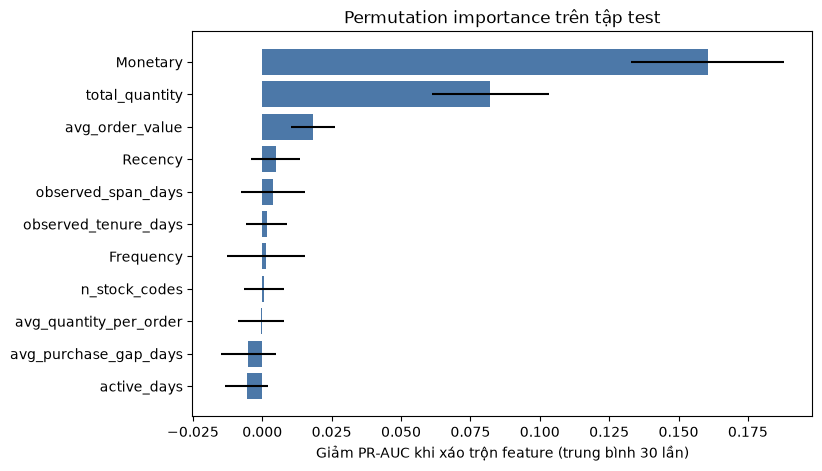

,feature,perm_mean,perm_std,impurity
0,Monetary,0.1605,0.0276,0.2834
1,total_quantity,0.0822,0.0210,0.2022
2,avg_order_value,0.0183,0.0079,0.0801
3,Recency,0.0048,0.0088,0.0430
4,observed_span_days,0.0038,0.0116,0.0402
5,observed_tenure_days,0.0015,0.0072,0.0436
6,Frequency,0.0013,0.0140,0.0553
7,n_stock_codes,0.0005,0.0073,0.1041
8,avg_quantity_per_order,-0.0003,0.0082,0.0557
9,avg_purchase_gap_days,-0.0051,0.0099,0.0495


In [16]:
perm = permutation_importance(best_rf, X_test, y_test, scoring="average_precision",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
imp = (pd.DataFrame({"feature": X_test.columns, "perm_mean": perm.importances_mean,
                     "perm_std": perm.importances_std, "impurity": best_rf.feature_importances_})
       .sort_values("perm_mean", ascending=False).reset_index(drop=True))
results["importance"] = imp.round(5).to_dict("records")

fig, ax = plt.subplots(figsize=(8, 5))
d = imp.sort_values("perm_mean")
ax.barh(d["feature"], d["perm_mean"], xerr=d["perm_std"], color="#4C78A8")
ax.set(xlabel="Giảm PR-AUC khi xáo trộn feature (trung bình 30 lần)", title="Permutation importance trên tập test")
plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()
imp.round(4)

Chỉ Monetary (giảm PR-AUC 0,161) và total_quantity (0,082) có tác động rõ; avg_order_value thấp (0,018); các feature còn lại gần 0 hoặc âm, tức nằm trong nhiễu. Điều này khớp với kết quả baseline: mô hình chủ yếu dựa vào quy mô chi tiêu đã có. Monetary và total_quantity tương quan cao (Spearman khoảng 0,93 trên cả kỳ) nên mức quan trọng của từng cái có thể bị chia sẻ. Impurity importance xếp `n_stock_codes` cao (0,10) trong khi permutation gần 0, nên chỉ dùng permutation để kết luận.

## Tổng hợp kết quả

In [17]:
from IPython.display import display, JSON
summary = pd.DataFrame({
    "Chỉ số": ["Khách trong cohort", "Khách đưa vào mô hình", "Train / Test", "Ngưỡng top 20% (GBP)",
               "PR-AUC test (RF)", "PR-AUC test (baseline Monetary)", "Precision@10% (RF)", "Lift@10% (RF)"],
    "Giá trị": [results["n_cohort"], results["cohort_funnel"]["n_with_features"],
                f'{results["label"]["n_train"]} / {results["label"]["n_test"]}',
                round(results["label"]["thr_gbp"]),
                results["test"]["rank"]["Random Forest"]["PR-AUC"],
                results["test"]["rank"]["Baseline: Monetary quá khứ"]["PR-AUC"],
                results["test"]["rank"]["Random Forest"]["Precision@10%"],
                results["test"]["rank"]["Random Forest"]["Lift@10%"]],
})
display(summary)
display(JSON(json.loads(json.dumps(results, default=lambda o: o.item() if hasattr(o, "item") else str(o)))))

,Chỉ số,Giá trị
0,Khách trong cohort,4327
1,Khách đưa vào mô hình,3306
2,Train / Test,2644 / 662
3,Ngưỡng top 20% (GBP),922
4,PR-AUC test (RF),0.6718
5,PR-AUC test (baseline Monetary),0.6784
6,Precision@10% (RF),0.8485
7,Lift@10% (RF),4.2233


<IPython.core.display.JSON object>

**Kết luận:** với 11 feature này, Random Forest dự đoán khách giá trị cao tốt hơn hẳn đoán ngẫu nhiên (PR-AUC 0,67 so với 0,20) nhưng không hơn quy tắc đơn giản dựa trên Monetary quá khứ. Phần lớn thông tin dự đoán nằm ở quy mô chi tiêu đã có.

**Giới hạn:**
- Dữ liệu chỉ một năm, giai đoạn nhãn 3,3 tháng trùng mùa Giáng sinh, chỉ một mốc cắt và test 662 khách nên khoảng bootstrap rộng
- Mốc top 20% là lựa chọn tùy ý
- Cohort dựa trên cleaning legacy chưa được nhóm duyệt; chưa đánh giá khách mới (1.021 khách)
- Permutation importance cho thấy mức liên quan tới dự đoán, không phải quan hệ nhân quả

**Hướng tiếp theo (chưa làm):** thêm feature theo thời gian gần (chi tiêu 30/60 ngày cuối giai đoạn feature, tỷ lệ hủy), thử nhiều mốc cắt để ước lượng ổn định hơn, mở rộng lưới `min_samples_leaf`.